# Quickstart: shared data, models and outputs

A short tour of everything both pairs share: the dataset, the two models and the files written by
`make inference` and `make baselines`. It only shows **what exists and how to load it**; the actual
analysis happens in each pair's own folder (`phase1/pair_a/notebooks/`, ...).

**Needs:** the `ai-and-vis` environment and these files (see README):
- `data/iwildcam_v2.0/` and the WILDS checkpoint (`make data`)
- `outputs/predictions.parquet` (`make inference`)
- `outputs/predictions_probe.parquet`, `outputs/baselines.csv`, `checkpoints/linear_probe.pt` (`make baselines`)

Please don't edit this notebook for your own work; copy it into your pair's folder instead.
Its outputs are committed on purpose (notebook metadata `keep_output: true`), so it can be read
without running it. After changing it, rerun all cells before committing.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

from common import ROOT, load_config, resolve
from common.data import get_transform, load_class_names, load_metadata, normalize
from common.model import get_device, load_model, load_probe_model

cfg = load_config()
paths = {key: resolve(value) for key, value in cfg["paths"].items()}
for key in ["data_dir", "checkpoint", "predictions", "predictions_probe", "baselines", "probe_checkpoint"]:
    print(f"{key:18s} {'ok' if paths[key].exists() else 'MISSING'}   {paths[key].relative_to(ROOT)}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

data_dir           ok   data/iwildcam_v2.0
checkpoint         ok   checkpoints/iwildcam_erm_seed0_best_model.pth
predictions        ok   outputs/predictions.parquet
predictions_probe  ok   outputs/predictions_probe.parquet
baselines          ok   outputs/baselines.csv
probe_checkpoint   ok   checkpoints/linear_probe.pt
GPU: NVIDIA GeForce RTX 5080


## 1. Dataset at a glance

WILDS iWildCam v2.0: camera-trap images, 182 classes (species plus `empty`). Every image belongs to one split:

| Split | Camera locations |
|---|---|
| `train` | training cameras |
| `id_val`, `id_test` | the **same** cameras as `train` (in-distribution) |
| `val`, `test` | cameras **never seen** in training (distribution shift) |

All settings (splits, paths, seed, ...) come from `common/config.yaml`.

In [ ]:
meta = load_metadata(cfg)
overview = meta.groupby("split").agg(
    images=("y", "size"), classes=("y", "nunique"), camera_locations=("location_remapped", "nunique")
)
overview.loc[["train", "id_val", "val", "id_test", "test"]]

,images,classes,camera_locations
split,,,
train,129809,182,243
id_val,7314,71,146
val,14961,75,32
id_test,8154,87,164
test,42791,102,48


## 2. Predictions files

Both models' predictions on the evaluation splits, **one row per image, same rows in the same order**:

- `outputs/predictions.parquet`: WILDS fine-tuned ResNet-50 (`make inference`)
- `outputs/predictions_probe.parquet`: frozen ImageNet ResNet-50 + linear probe (`make baselines`)

Columns: `id`, `split`, `label`/`label_name` (truth), `prediction`/`prediction_name`, `confidence`
(max probability), the metadata columns (location, sequence, datetime, filename, ...) and the full
probability distribution `prob_0` ... `prob_181`.

In [ ]:
finetuned = pd.read_parquet(paths["predictions"])
probe = pd.read_parquet(paths["predictions_probe"])
print("fine-tuned:", finetuned.shape, "| probe:", probe.shape)
print("same images in the same order:", finetuned["id"].equals(probe["id"]))

prob_cols = [c for c in finetuned.columns if c.startswith("prob_")]
print(f"{len(prob_cols)} probability columns; every row sums to 1:",
      np.allclose(finetuned[prob_cols].sum(axis=1), 1, atol=1e-4))

finetuned[["id", "split", "label_name", "prediction_name", "confidence", "location", "datetime", "filename"]].head()

fine-tuned: (73220, 196) | probe: (73220, 196)
same images in the same order: True
182 probability columns; every row sums to 1: True


,id,split,label_name,prediction_name,confidence,location,datetime,filename
0,879ef740-21bc-11ea-a13a-137349068a90,id_val,leopardus pardalis,leopardus pardalis,0.989588,3,2013-04-15 05:14:07.000,879ef740-21bc-11ea-a13a-137349068a90.jpg
1,86ef629e-21bc-11ea-a13a-137349068a90,id_val,leopardus pardalis,leopardus pardalis,0.999767,3,2013-04-15 05:14:08.000,86ef629e-21bc-11ea-a13a-137349068a90.jpg
2,97c4fca0-21bc-11ea-a13a-137349068a90,id_val,leopardus pardalis,leopardus pardalis,0.999757,3,2013-04-15 05:14:08.000,97c4fca0-21bc-11ea-a13a-137349068a90.jpg
3,8cbb6e3e-21bc-11ea-a13a-137349068a90,id_val,leopardus pardalis,leopardus pardalis,0.996260,3,2013-04-15 05:14:09.000,8cbb6e3e-21bc-11ea-a13a-137349068a90.jpg
4,95bf1f9e-21bc-11ea-a13a-137349068a90,id_val,leopardus pardalis,leopardus pardalis,0.995463,3,2013-04-15 05:14:10.000,95bf1f9e-21bc-11ea-a13a-137349068a90.jpg


## 3. Baseline metrics

Official WILDS metrics per model and split (from `outputs/baselines.csv`): accuracy and macro F1
(macro recall is in the CSV too). "Majority class" always predicts `empty`.

In [ ]:
baselines = pd.read_csv(paths["baselines"])
splits = ["id_val", "val", "id_test", "test"]
table = baselines.pivot_table(index="split", columns="model", values=["acc", "f1_macro"]).loc[splits]
table.round(3)

acc                                          \
model   ImageNet linear probe Majority class (empty) WILDS fine-tuned   
split                                                                   
id_val                  0.788                  0.404            0.823   
val                     0.524                  0.160            0.612   
id_test                 0.736                  0.246            0.760   
test                    0.657                  0.330            0.702   

                     f1_macro                                          
model   ImageNet linear probe Majority class (empty) WILDS fine-tuned  
split                                                                  
id_val                  0.432                  0.008            0.479  
val                     0.293                  0.004            0.366  
id_test                 0.457                  0.005            0.474  
test                    0.239                  0.005            0.323

## 4. Example images

Eight test images drawn **at random** (fixed seed), not selected for being interesting, with the
true label and both models' predictions (confidence in brackets).

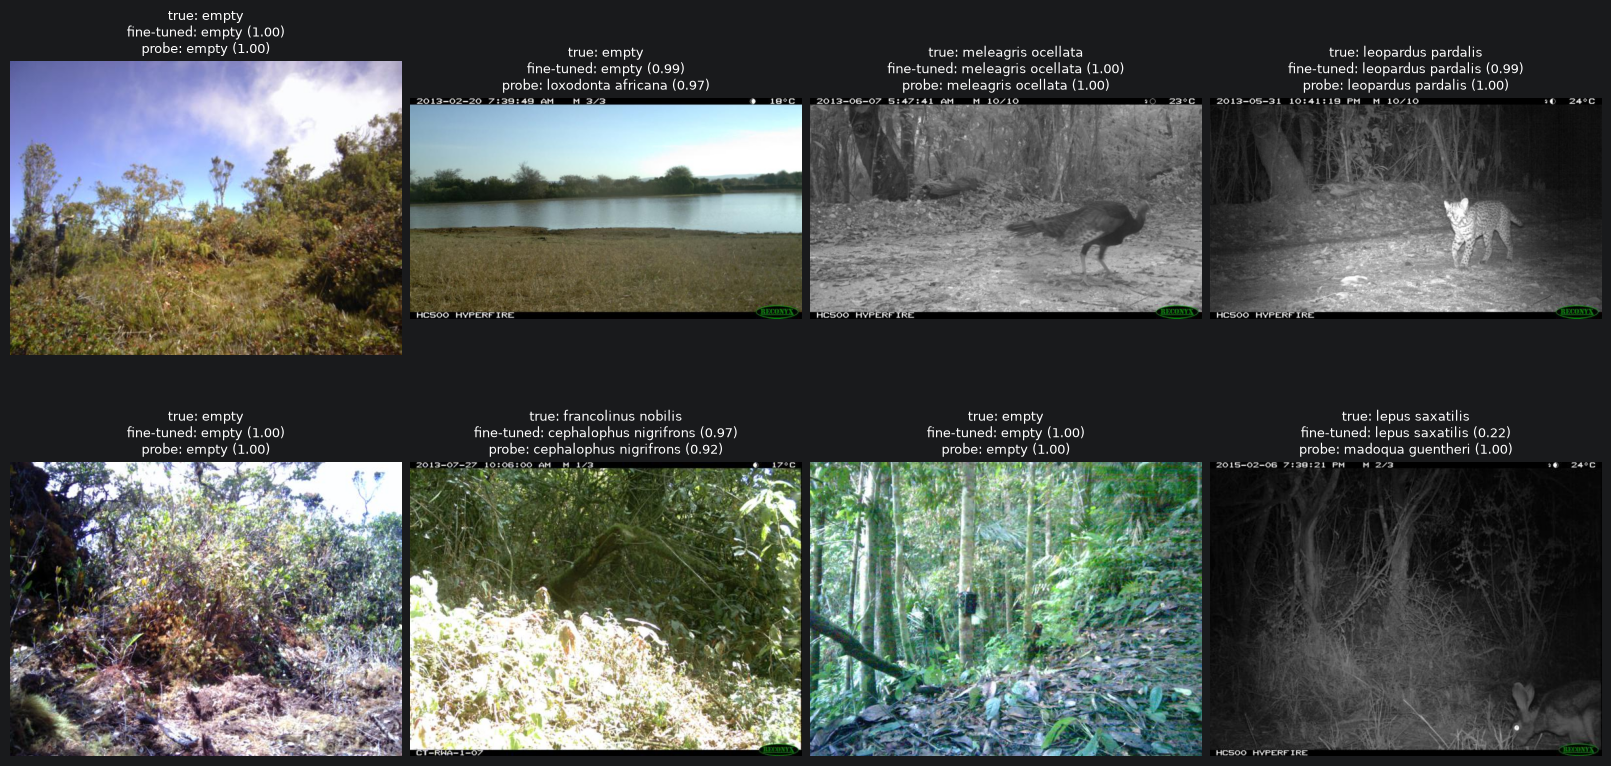

In [ ]:
sample = finetuned[finetuned["split"] == "test"].sample(8, random_state=cfg["seed"])

fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout="constrained")
for ax, (i, row) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(paths["data_dir"] / "train" / row["filename"]))
    p = probe.loc[i]  # same row index in both files
    ax.set_title(f"true: {row['label_name']}\n"
                 f"fine-tuned: {row['prediction_name']} ({row['confidence']:.2f})\n"
                 f"probe: {p['prediction_name']} ({p['confidence']:.2f})", fontsize=9)
    ax.axis("off")
plt.show()

## 5. Using the models directly

For Phase II you'll need the models themselves, not only their predictions:

- `load_model(cfg)`: WILDS fine-tuned ResNet-50
- `load_probe_model(cfg)`: ImageNet ResNet-50 + linear probe

Both take **normalized** images: `get_transform(cfg)` (resize to 448﷿﷿448) followed by `normalize`.
They return logits over the 182 classes. Here, both models run on the first example image; the
result matches the predictions files.

In [ ]:
device = get_device(cfg)
models = {"fine-tuned": load_model(cfg, device), "probe": load_probe_model(cfg, device)}
names = load_class_names(cfg)

row = sample.iloc[0]
image = Image.open(paths["data_dir"] / "train" / row["filename"]).convert("RGB")
x = normalize(get_transform(cfg)(image).unsqueeze(0).to(device))  # [1, 3, 448, 448]

files = {"fine-tuned": finetuned, "probe": probe}
print("true label:", row["label_name"])
with torch.no_grad():
    for name, model in models.items():
        probs = torch.softmax(model(x), dim=1)[0].cpu()
        top = probs.topk(3)
        top3 = ", ".join(f"{names[int(c)]} {p:.3f}" for p, c in zip(top.values, top.indices))
        from_file = files[name].loc[row.name, prob_cols].to_numpy(dtype=np.float32)
        print(f"{name:10s} top-3: {top3}   | matches predictions file: {np.allclose(probs.numpy(), from_file, atol=1e-3)}")

true label: empty
fine-tuned top-3: empty 1.000, giraffa camelopardalis 0.000, helarctos malayanus 0.000   | matches predictions file: True
probe      top-3: empty 1.000, muntiacus muntjak 0.000, sus scrofa 0.000   | matches predictions file: True


## 6. Embeddings (optional)

The 2048-d penultimate-layer features of both models, row-aligned with the predictions files. They
are only written if `inference.save_embeddings: true` in `common/config.yaml` (about 600 MB each);
then rerun `make inference` and `make baselines`.

In [ ]:
for key in ["embeddings", "embeddings_imagenet"]:
    if paths[key].exists():
        print(f"{key:20s}", np.load(paths[key], mmap_mode="r").shape)
    else:
        print(f"{key:20s} not created (set inference.save_embeddings: true and rerun)")

embeddings           not created (set inference.save_embeddings: true and rerun)
embeddings_imagenet  not created (set inference.save_embeddings: true and rerun)
